# BlinkIT Grocery Sales Analysis
**Domain:** Retail & Grocery Sales Analytics  |  **Company:** Sapphire IQ  |  **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

**Business context:** Ram, a Data Analyst at Sapphire IQ, has to study BlinkIT grocery sales data and tell management which products, categories, outlets and locations are performing well, where there is scope to improve, and what to do next.

**How this notebook is organised (follows the four project objectives):**
1. Understand the business and its sales performance
2. Make sure the available information is reliable (data cleaning)
3. Find out what is driving better sales performance
4. Help management make better business decisions

> Keep `BlinkIT_Grocery_Data.xlsx` in the same folder as this notebook. If `read_excel` fails, run `pip install openpyxl` once.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

df = pd.read_excel('BlinkIT_Grocery_Data.xlsx')
raw = df.copy()            # untouched copy, used for the data-quality checks in Objective 2
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


---
# Objective 1: Understand the Business and Its Sales Performance
## Task 1.1: What types of products is BlinkIT selling?

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 1.2 MB


Unique products (Item Identifier): 1559
Item types (categories)          : 16

Fat content labels as found in the raw data:
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


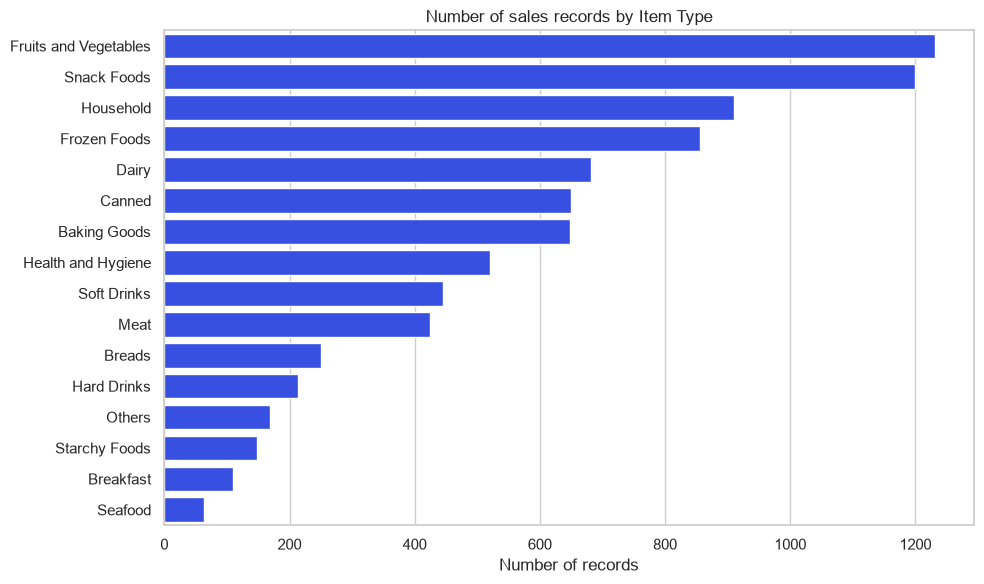

In [3]:
print('Unique products (Item Identifier):', df['Item Identifier'].nunique())
print('Item types (categories)          :', df['Item Type'].nunique())
print()
print('Fat content labels as found in the raw data:')
print(df['Item Fat Content'].value_counts())

item_type_counts = df['Item Type'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=item_type_counts.values, y=item_type_counts.index, color='#1A3CFF')
plt.title('Number of sales records by Item Type')
plt.xlabel('Number of records'); plt.ylabel('')
plt.tight_layout(); plt.show()

**Insight 1.1:** BlinkIT sells **1,559 different products** across **16 item types**. *Fruits and Vegetables* and *Snack Foods* have the most records (about 1,200 each), while *Seafood*, *Breakfast* and *Starchy Foods* are small segments. The fat-content column uses 5 labels for what are really 2 values (Low Fat / Regular). This is fixed in Task 2.4.

## Task 1.2: What types and locations of outlets does BlinkIT have?

In [4]:
check = df.groupby('Outlet Identifier')[['Outlet Type', 'Outlet Location Type', 'Outlet Size',
                                         'Outlet Establishment Year']].nunique()
print('Different values recorded per outlet (an outlet should have exactly 1):')
print(check)
print()
outlets = df.groupby('Outlet Identifier').agg(
    Outlet_Type=('Outlet Type', 'first'),
    Location_Tier=('Outlet Location Type', 'first'),
    Size=('Outlet Size', lambda s: s.iloc[0] if s.nunique() == 1 else 'Mixed'),
    Established=('Outlet Establishment Year', 'first'),
    Records=('Sales', 'size'))
outlets

Different values recorded per outlet (an outlet should have exactly 1):
                   Outlet Type  Outlet Location Type  Outlet Size  \
Outlet Identifier                                                   
OUT010                       1                     1            3   
OUT013                       1                     1            1   
OUT017                       1                     1            3   
OUT018                       1                     1            1   
OUT019                       1                     1            1   
OUT027                       1                     1            1   
OUT035                       1                     1            1   
OUT045                       1                     1            3   
OUT046                       1                     1            1   
OUT049                       1                     1            1   

                   Outlet Establishment Year  
Outlet Identifier                             
OUT01

,Outlet_Type,Location_Tier,Size,Established,Records
Outlet Identifier,,,,,
OUT010,Grocery Store,Tier 3,Mixed,2011,555
OUT013,Supermarket Type1,Tier 3,High,2014,932
OUT017,Supermarket Type1,Tier 2,Mixed,2020,926
OUT018,Supermarket Type2,Tier 3,Medium,2022,928
OUT019,Grocery Store,Tier 1,Small,2018,528
OUT027,Supermarket Type3,Tier 3,Medium,2018,935
OUT035,Supermarket Type1,Tier 2,Small,2017,930
OUT045,Supermarket Type1,Tier 2,Mixed,2015,929
OUT046,Supermarket Type1,Tier 1,Small,2016,930


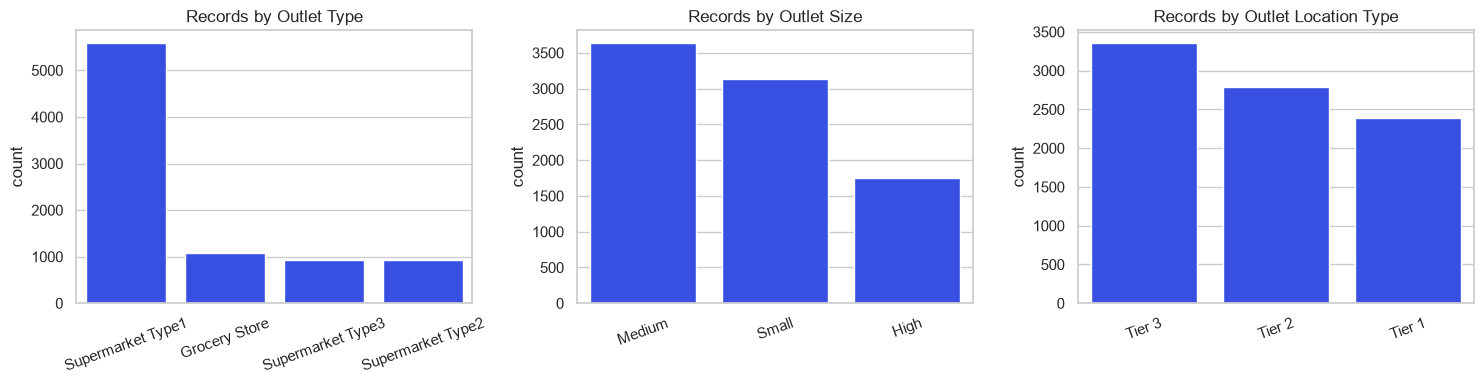

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Outlet Type', 'Outlet Size', 'Outlet Location Type']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color='#1A3CFF', ax=ax)
    ax.set_title(f'Records by {col}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Insight 1.2:** BlinkIT operates **10 outlets** of **4 types** (Supermarket Type1/2/3 and Grocery Store) in **3 location tiers** (Tier 1/2/3). Supermarket Type1 is the most common format: **6 of the 10 outlets** and about 65% of records. The two Grocery Stores (OUT010 and OUT019) have about 40% fewer records than the other eight outlets.

**Data issue spotted:** an outlet has only one physical size, yet **OUT010, OUT017 and OUT045 carry all three sizes (High, Medium and Small)** in different records. Type, tier and establishment year are consistent. This is handled in Task 2.4.

## Task 1.3: How much is BlinkIT selling overall?

Total sales          : 1,201,681
Average sale / record: 140.99
Median sale / record : 143.01
Lowest / Highest     : 31.29 / 266.89
Number of records    : 8,523


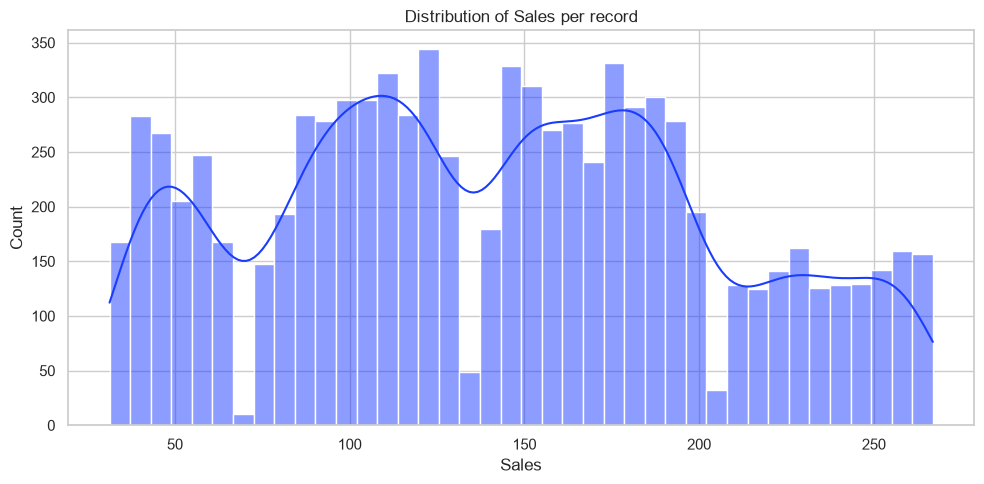

In [6]:
total_sales = df['Sales'].sum()
print(f'Total sales          : {total_sales:,.0f}')
print(f'Average sale / record: {df["Sales"].mean():,.2f}')
print(f'Median sale / record : {df["Sales"].median():,.2f}')
print(f'Lowest / Highest     : {df["Sales"].min():,.2f} / {df["Sales"].max():,.2f}')
print(f'Number of records    : {len(df):,}')

sns.histplot(df['Sales'], bins=40, kde=True, color='#1A3CFF')
plt.title('Distribution of Sales per record')
plt.xlabel('Sales'); plt.tight_layout(); plt.show()

**Insight 1.3:** Total sales across all 8,523 records are about **12.0 lakh (1,201,681)**, with an average of about **141 per record** (the dataset does not state the currency unit). Individual sales range from about 31 to 267. They are spread widely, with a few separate peaks (around 40, 110 and 170) instead of one bell-shaped curve, which points to a mix of low-, mid- and high-value products. There are no extreme spikes or outliers.

## Task 1.4: What is the overall customer rating and product performance?

Average rating: 3.97   Median rating: 4.0

Rating
1.0     118
2.0     198
3.0     609
4.0    6913
5.0     685
Name: Records (rating rounded), dtype: int64


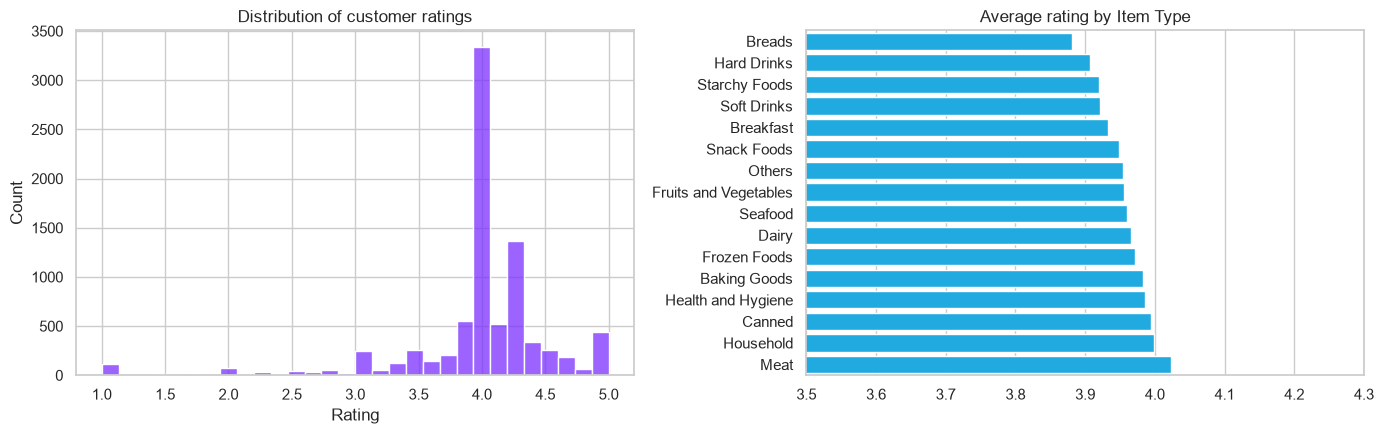

,Total_Sales,Avg_Rating,Records
Item Identifier,,,
FDU12,2371.01,4.14,9
FDT07,2306.90,4.00,9
NCQ06,2294.71,4.12,9
FDL58,2111.65,3.86,8
NCB31,2104.73,3.84,8
FDX31,2104.46,4.06,9
FDF05,2103.13,3.90,8
FDR59,2096.58,3.79,8
FDP28,2087.85,4.21,8


In [7]:
print(f'Average rating: {df["Rating"].mean():.2f}   Median rating: {df["Rating"].median():.1f}')
print()
print(df['Rating'].round(0).value_counts().sort_index().rename('Records (rating rounded)'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df['Rating'], bins=30, color='#7B2FFF', ax=axes[0])
axes[0].set_title('Distribution of customer ratings')
rating_by_type = df.groupby('Item Type')['Rating'].mean().sort_values()
sns.barplot(x=rating_by_type.values, y=rating_by_type.index, color='#00B8FF', ax=axes[1])
axes[1].set_xlim(3.5, 4.3); axes[1].set_title('Average rating by Item Type'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

top_products = (df.groupby('Item Identifier')
                  .agg(Total_Sales=('Sales', 'sum'), Avg_Rating=('Rating', 'mean'), Records=('Sales', 'size'))
                  .sort_values('Total_Sales', ascending=False).head(10).round(2))
top_products

**Insight 1.4:** Customers are generally satisfied: the **average rating is 3.97 out of 5**, and 4.0 is by far the most common score. Average ratings are almost the same across item types (all close to 4), so rating alone does not separate strong products from weak ones. The table above lists the 10 products with the highest total sales.

---
# Objective 2: Make Sure the Available Information Is Reliable
## Task 2.1: Find information that is missing

In [8]:
missing = raw.isnull().sum().to_frame('Missing values')
missing['Percent'] = (missing['Missing values'] / len(raw) * 100).round(2)
print(missing[missing['Missing values'] > 0])
print()
print('Outlets where Item Weight is missing:')
print(raw[raw['Item Weight'].isnull()].groupby('Outlet Identifier').size())
print()
print('Records with Item Visibility = 0 (a displayed item cannot have zero visibility):',
      (raw['Item Visibility'] == 0).sum())

             Missing values  Percent
Item Weight            1463    17.17

Outlets where Item Weight is missing:
Outlet Identifier
OUT019    528
OUT027    935
dtype: int64

Records with Item Visibility = 0 (a displayed item cannot have zero visibility): 526


**What we found:** `Item Weight` is missing in **1,463 records (17%)**, and *all* of them come from two outlets (OUT019 and OUT027). In addition, **526 records show `Item Visibility = 0`**, which is not realistic for a product that was sold, so we treat it as missing too.

**How we fix it:** every product has one fixed weight, so a missing weight is filled from the other records of the *same product*. A zero visibility is replaced by the product's average non-zero visibility. Only 4 records could not be filled this way, and they use the median weight of their item type.

In [9]:
# --- Item Weight ---
print('Max different weights recorded for one product:', df.groupby('Item Identifier')['Item Weight'].nunique().max())
product_weight = df.groupby('Item Identifier')['Item Weight'].transform('mean')
df['Item Weight'] = df['Item Weight'].fillna(product_weight)
still_missing = df['Item Weight'].isnull().sum()
print('Weight still missing after using same-product weight:', still_missing)
df['Item Weight'] = df['Item Weight'].fillna(df.groupby('Item Type')['Item Weight'].transform('median'))

# --- Item Visibility ---
vis = df['Item Visibility'].replace(0, np.nan)
df['Item Visibility'] = vis.fillna(vis.groupby(df['Item Identifier']).transform('mean'))
df['Item Visibility'] = df['Item Visibility'].fillna(vis.median())

print()
print('Missing values after cleaning :', int(df.isnull().sum().sum()))
print('Zero visibility after cleaning:', int((df['Item Visibility'] == 0).sum()))

Max different weights recorded for one product: 1
Weight still missing after using same-product weight: 4

Missing values after cleaning : 0
Zero visibility after cleaning: 0


## Task 2.2: Find information that is repeated

In [10]:
print('Completely duplicate rows                       :', raw.duplicated().sum())
print('Repeated Item + Outlet combinations             :', raw.duplicated(subset=['Item Identifier', 'Outlet Identifier']).sum())
print('Products that appear in more than one outlet    :', (raw.groupby('Item Identifier')['Outlet Identifier'].nunique() > 1).sum())
print('Max outlets selling the same product            :', raw.groupby('Item Identifier')['Outlet Identifier'].nunique().max())

Completely duplicate rows                       : 0
Repeated Item + Outlet combinations             : 0
Products that appear in more than one outlet    : 1550
Max outlets selling the same product            : 10


**Conclusion 2.2:** There are **no duplicate records**. A product code (Item Identifier) naturally repeats because the same product is sold in several outlets, and each product appears at most once per outlet. So nothing needs to be removed.

## Task 2.3: Find unusually high or low values

                 Lower limit  Upper limit  Outliers     Min      Max
Item Visibility       -0.070        0.200     144.0   0.004    0.328
Item Weight           -3.313       28.948       0.0   4.555   21.350
Sales                -43.899      323.370       0.0  31.290  266.888
Rating                 3.700        4.500    1931.0   1.000    5.000


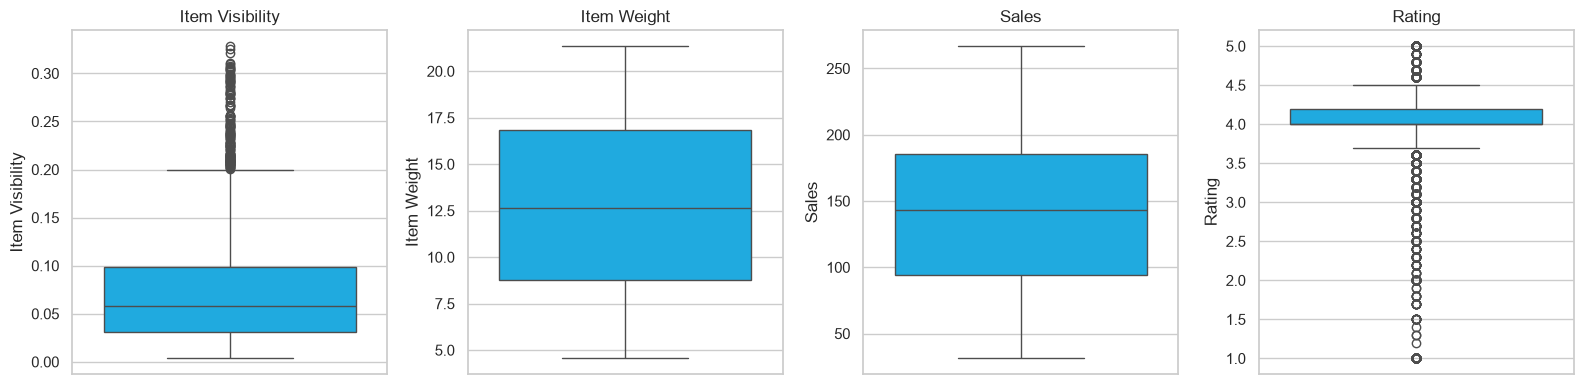

In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'Lower limit': round(low, 3), 'Upper limit': round(high, 3),
                      'Outliers': int(((s < low) | (s > high)).sum()),
                      'Min': round(s.min(), 3), 'Max': round(s.max(), 3)})

num_cols = ['Item Visibility', 'Item Weight', 'Sales', 'Rating']
print(df[num_cols].apply(iqr_outliers).T)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='#00B8FF'); ax.set_title(col)
plt.tight_layout(); plt.show()

**Conclusion 2.3:**
- **Sales** and **Item Weight** have **no outliers**.
- **Item Visibility** has about 144 high values (above about 0.20, up to 0.33). These are real products placed prominently, so they are **kept**.
- **Rating** is flagged for about 1,900 records only because most ratings sit exactly at 4.0, which makes the allowed range very narrow. Ratings between 1 and 5 are valid, so they are **kept**.

No records are removed. Every flagged value is a genuine, possible value.

## Task 2.4: Present similar information in the same way

In [12]:
# 1) Fat content: 5 labels -> 2
print('Before:'); print(df['Item Fat Content'].value_counts())
df['Item Fat Content'] = df['Item Fat Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

# 2) Tidy any stray spaces in text columns
for col in df.select_dtypes(include='object').columns.tolist() + df.select_dtypes(include='string').columns.tolist():
    df[col] = df[col].str.strip()

# 3) Item Category from the product code prefix: FD = Food, DR = Drinks, NC = Non-Consumable
df['Item Category'] = df['Item Identifier'].str[:2].map({'FD': 'Food', 'DR': 'Drinks', 'NC': 'Non-Consumable'})
print()
print('Fat content for Non-Consumable items (soap, household etc.) before fixing:')
print(df[df['Item Category'] == 'Non-Consumable']['Item Fat Content'].value_counts())

# 4) Non-consumables cannot be Low Fat / Regular -> mark as 'Non-Edible'
df.loc[df['Item Category'] == 'Non-Consumable', 'Item Fat Content'] = 'Non-Edible'
print()
print('After:'); print(df['Item Fat Content'].value_counts())
print()
print(pd.crosstab(df['Item Category'], df['Item Fat Content']))

Before:
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Fat content for Non-Consumable items (soap, household etc.) before fixing:
Item Fat Content
Low Fat    1599
Name: count, dtype: int64

After:
Item Fat Content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64

Item Fat Content  Low Fat  Non-Edible  Regular
Item Category                                 
Drinks                728           0       71
Food                 3190           0     2935
Non-Consumable          0        1599        0


**Conclusion 2.4 (part 1):** The five fat-content labels are merged into **Low Fat** and **Regular**. A new column **Item Category** (Food / Drinks / Non-Consumable) is created from the product code, and non-consumable items (household, health & hygiene, etc.), which cannot have a fat level, are labelled **Non-Edible**.

In [13]:
# 5) Outlet Size: an outlet has ONE size, but three outlets show all three sizes in different records
size_check = df.groupby('Outlet Identifier')['Outlet Size'].nunique()
print('Outlets with more than one size recorded:', size_check[size_check > 1].index.tolist())
print()
print(df[df['Outlet Identifier'].isin(size_check[size_check > 1].index)]
        .groupby(['Outlet Identifier', 'Outlet Size']).size().unstack(fill_value=0))

# We cannot tell which size is correct (the counts are almost evenly split), so we do NOT guess:
# those outlets are labelled 'Unclear' in a new column, and the original column is left untouched.
size_map = df.groupby('Outlet Identifier')['Outlet Size'].agg(lambda s: s.iloc[0] if s.nunique() == 1 else 'Unclear')
df['Outlet Size (clean)'] = df['Outlet Identifier'].map(size_map)
print()
print(size_map)

Outlets with more than one size recorded: ['OUT010', 'OUT017', 'OUT045']

Outlet Size        High  Medium  Small
Outlet Identifier                     
OUT010              233     265     57
OUT017              314     244    368
OUT045              274     329    326

Outlet Identifier
OUT010    Unclear
OUT013       High
OUT017    Unclear
OUT018     Medium
OUT019      Small
OUT027     Medium
OUT035      Small
OUT045    Unclear
OUT046      Small
OUT049     Medium
Name: Outlet Size, dtype: str


**Conclusion 2.4 (part 2):** For OUT010, OUT017 and OUT045 the size labels are split almost evenly between High, Medium and Small, so there is no safe way to pick the right one. Instead of guessing, these outlets are labelled **Unclear** in a new column (`Outlet Size (clean)`). Size-based conclusions later in this notebook therefore rest on the 7 outlets with a consistent size, and this field should be corrected at the source. All other text columns are now consistent, and the cleaned `df` is used from here on.

---
# Objective 3: Find Out What Is Driving Better Sales Performance
## Task 3.1: Which types of products are selling more?

                       Total_Sales  Avg_Sales_per_Record  Records  Share_%
Item Type                                                                 
Fruits and Vegetables     178124.1                 144.6     1232     14.8
Snack Foods               175433.9                 146.2     1200     14.6
Household                 135976.5                 149.4      910     11.3
Frozen Foods              118558.9                 138.5      856      9.9
Dairy                     101276.5                 148.5      682      8.4
Canned                     90706.7                 139.8      649      7.5
Baking Goods               81894.7                 126.4      648      6.8
Health and Hygiene         68025.8                 130.8      520      5.7
Meat                       59449.9                 139.9      425      4.9
Soft Drinks                58514.2                 131.5      445      4.9
Breads                     35379.1                 141.0      251      2.9
Hard Drinks              

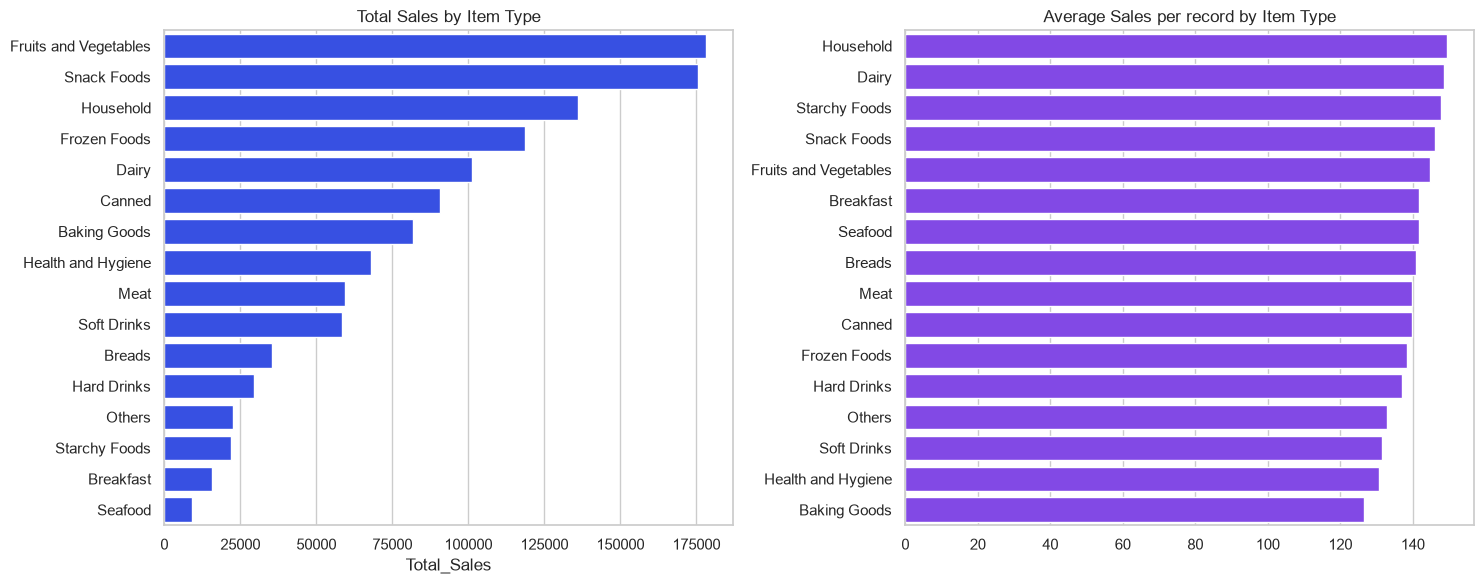

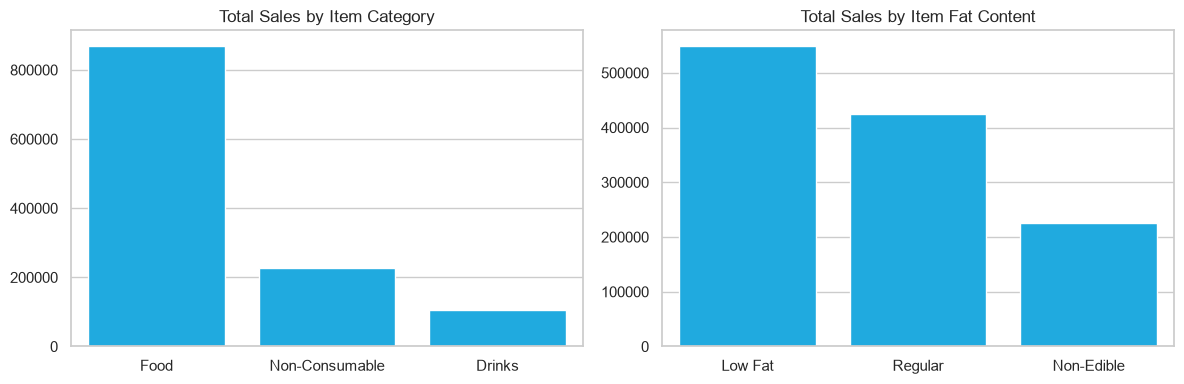

In [14]:
type_perf = (df.groupby('Item Type')['Sales']
               .agg(Total_Sales='sum', Avg_Sales_per_Record='mean', Records='size')
               .sort_values('Total_Sales', ascending=False).round(1))
type_perf['Share_%'] = (type_perf['Total_Sales'] / type_perf['Total_Sales'].sum() * 100).round(1)
print(type_perf)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=type_perf['Total_Sales'], y=type_perf.index, color='#1A3CFF', ax=axes[0])
axes[0].set_title('Total Sales by Item Type'); axes[0].set_ylabel('')
avg_sorted = type_perf['Avg_Sales_per_Record'].sort_values(ascending=False)
sns.barplot(x=avg_sorted.values, y=avg_sorted.index, color='#7B2FFF', ax=axes[1])
axes[1].set_title('Average Sales per record by Item Type'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Item Category', 'Item Fat Content']):
    g = df.groupby(col)['Sales'].sum().sort_values(ascending=False)
    sns.barplot(x=g.index, y=g.values, color='#00B8FF', ax=ax); ax.set_title(f'Total Sales by {col}'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Insight 3.1:**
- **Fruits and Vegetables (14.8%)** and **Snack Foods (14.6%)** bring in the most total sales, and together with *Household* (11.3%) and *Frozen Foods* (9.9%) they make up about half of all sales.
- Per record, the picture changes: **Household (149.4)**, **Dairy (148.5)** and **Starchy Foods (147.8)** have the highest average sale. *Baking Goods (126.4)* and *Health and Hygiene (130.8)* are the lowest.
- So the leaders in total sales win mostly through **volume (number of records)**, while Household and Dairy earn more *per sale*.

## Task 3.2: Which types of outlets are performing better?

                   Total_Sales  Avg_Sales_per_Record  Records  Outlets  \
Outlet Type                                                              
Supermarket Type1     787549.9                 141.2     5577        6   
Grocery Store         151939.1                 140.3     1083        2   
Supermarket Type2     131477.8                 141.7      928        1   
Supermarket Type3     130714.7                 139.8      935        1   

                   Sales_per_Outlet  Share_%  
Outlet Type                                   
Supermarket Type1          131258.0     65.5  
Grocery Store               75970.0     12.6  
Supermarket Type2          131478.0     10.9  
Supermarket Type3          130715.0     10.9  

                     Total_Sales  Avg_Sales_per_Record  Records  Outlets  \
Outlet Size (clean)                                                        
Medium                  392669.3                 140.6     2793        3   
Small                   339024.9            

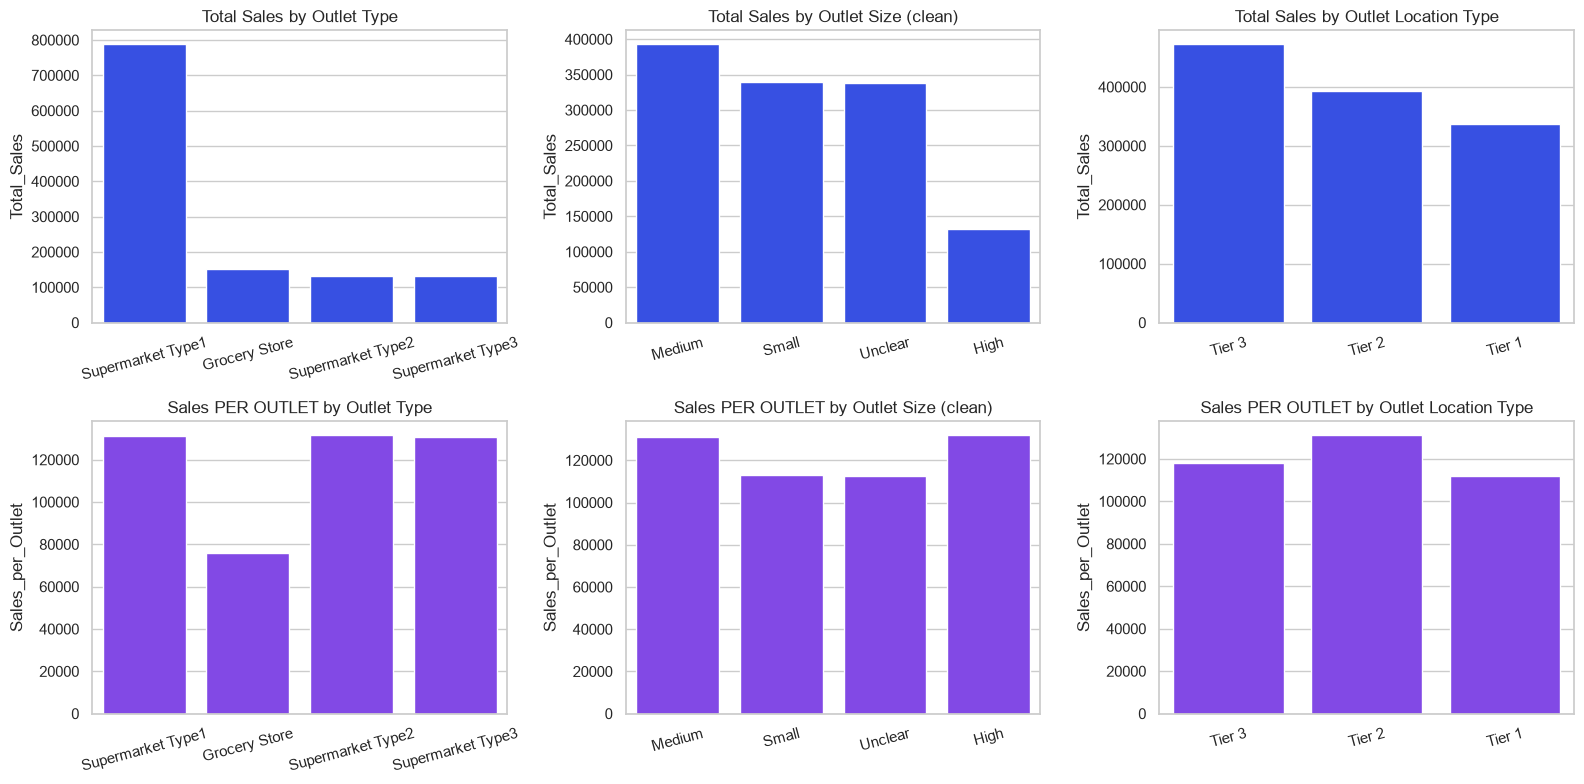

In [15]:
def outlet_summary(col):
    t = df.groupby(col).agg(Total_Sales=('Sales', 'sum'), Avg_Sales_per_Record=('Sales', 'mean'),
                            Records=('Sales', 'size'), Outlets=('Outlet Identifier', 'nunique'))
    t['Sales_per_Outlet'] = (t['Total_Sales'] / t['Outlets']).round(0)
    t['Share_%'] = (t['Total_Sales'] / t['Total_Sales'].sum() * 100).round(1)
    return t.round(1).sort_values('Total_Sales', ascending=False)

for col in ['Outlet Type', 'Outlet Size (clean)', 'Outlet Location Type']:
    print(outlet_summary(col)); print()

cols = ['Outlet Type', 'Outlet Size (clean)', 'Outlet Location Type']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(cols):
    t = outlet_summary(col)
    sns.barplot(x=t.index, y=t['Total_Sales'], color='#1A3CFF', ax=axes[0, i])
    axes[0, i].set_title(f'Total Sales by {col}')
    sns.barplot(x=t.index, y=t['Sales_per_Outlet'], color='#7B2FFF', ax=axes[1, i])
    axes[1, i].set_title(f'Sales PER OUTLET by {col}')
    for r in (0, 1):
        axes[r, i].set_xlabel(''); axes[r, i].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

**Insight 3.2:**
- On **total sales**, Supermarket Type1 looks dominant (787,550, **65.5%**), and Tier 3 and Medium look best. But these groups simply contain **more outlets** (Type1 has 6 outlets, Tier 3 has 4).
- On **sales per outlet** the picture is very different: every full supermarket earns about **131,000** (Type1 about 131,258, Type2 131,478, Type3 130,715). The **two Grocery Stores earn only about 75,970 each, roughly 58% of a supermarket**. Format, not tier or size, is what separates outlets.
- The **average sale per record is almost identical everywhere (about 140 to 142)**. Outlets with higher totals do not sell bigger baskets; they handle more records.
- Size note: three outlets have an unclear size (Task 2.4), so size results are indicative only.

## Task 3.3: Are product visibility, weight, ratings and outlet features connected with sales?

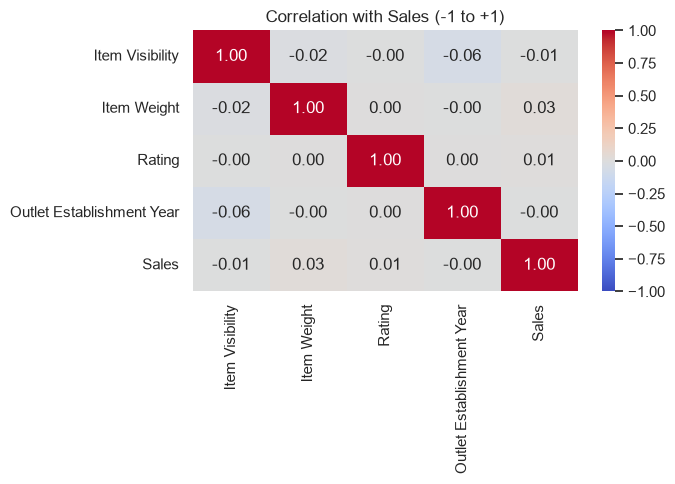

Item Visibility             -0.006
Item Weight                  0.026
Rating                       0.011
Outlet Establishment Year   -0.001
Name: Sales, dtype: float64


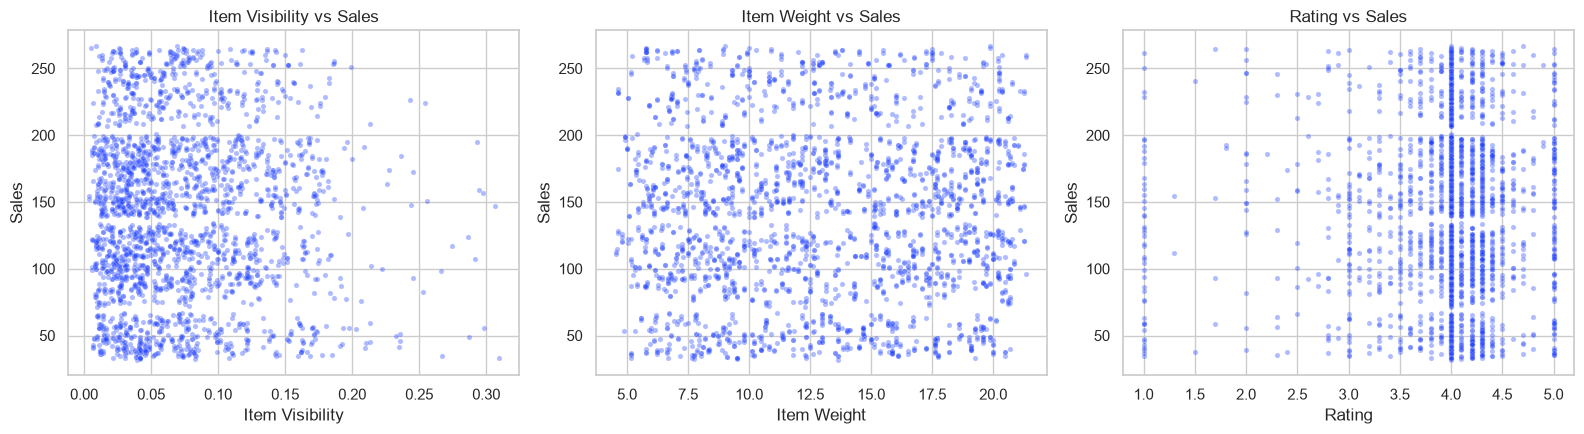

Visibility Band  Lowest 25%     Low    High  Highest 25%
mean                  141.0   137.2   148.4        137.4
size                 2131.0  2131.0  2130.0       2131.0 

Weight Band  Lightest 25%   Light   Heavy  Heaviest 25%
mean                137.8   141.4   139.4         145.4
size               2136.0  2169.0  2101.0        2117.0 

Rating Band  Up to 3.5  3.5-4.0  4.0-4.5  4.5-5.0
mean             139.3    142.2    139.7    140.9
size            1096.0   4255.0   2487.0    685.0 



In [16]:
corr_cols = ['Item Visibility', 'Item Weight', 'Rating', 'Outlet Establishment Year', 'Sales']
corr = df[corr_cols].corr().round(3)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation with Sales (-1 to +1)')
plt.tight_layout(); plt.show()
print(corr['Sales'].drop('Sales'))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['Item Visibility', 'Item Weight', 'Rating']):
    sns.scatterplot(data=df.sample(2500, random_state=1), x=col, y='Sales', alpha=0.35, s=14, ax=ax, color='#1A3CFF')
    ax.set_title(f'{col} vs Sales')
plt.tight_layout(); plt.show()

df['Visibility Band'] = pd.qcut(df['Item Visibility'], 4, labels=['Lowest 25%', 'Low', 'High', 'Highest 25%'])
df['Weight Band'] = pd.qcut(df['Item Weight'], 4, labels=['Lightest 25%', 'Light', 'Heavy', 'Heaviest 25%'])
df['Rating Band'] = pd.cut(df['Rating'], [0, 3.5, 4.0, 4.5, 5.0], labels=['Up to 3.5', '3.5-4.0', '4.0-4.5', '4.5-5.0'])
for band in ['Visibility Band', 'Weight Band', 'Rating Band']:
    print(df.groupby(band)['Sales'].agg(['mean', 'size']).round(1).T, '\n')

**Insight 3.3:** All correlations with Sales are essentially **zero (between -0.01 and +0.03)**. Grouping products into bands shows only small differences (average sale between about 137 and 148, within roughly +/-5% of the 141 overall average) and no steady pattern: for example, the "High" visibility band is highest, but the "Highest 25%" is not. Whether a product is highly visible or barely visible, light or heavy, highly rated or average, and whether the outlet is old or new, the average sale per record stays around 140. In this dataset **none of these factors explains sales differences**.

What this means for management: raising a product's shelf visibility or chasing a slightly higher rating will not by itself lift the value of each sale. The gains are in **volume** (more outlets, more products, more customers) and in **product mix** (Task 3.1).

## Task 3.4: Compare better-performing and lower-performing products and outlets

            Top 100 products  Bottom 100 products
Avg_Sales            254.370               40.176
Visibility             0.068                0.076
Weight                12.683               12.767
Rating                 3.983                3.942

Most common item types among TOP 100   : {'Dairy': 15, 'Snack Foods': 15, 'Frozen Foods': 15}
Most common item types among BOTTOM 100: {'Frozen Foods': 11, 'Fruits and Vegetables': 11, 'Snack Foods': 10}

                   Total_Sales  Avg_Sales  Records  Avg_Rating  \
Outlet Identifier                                                
OUT035                133103.9      143.1      930         3.9   
OUT046                132113.4      142.1      930         4.0   
OUT013                131809.0      141.4      932         3.9   
OUT018                131477.8      141.7      928         4.0   
OUT045                130942.8      141.0      929         4.0   
OUT027                130714.7      139.8      935         4.0   
OUT049          

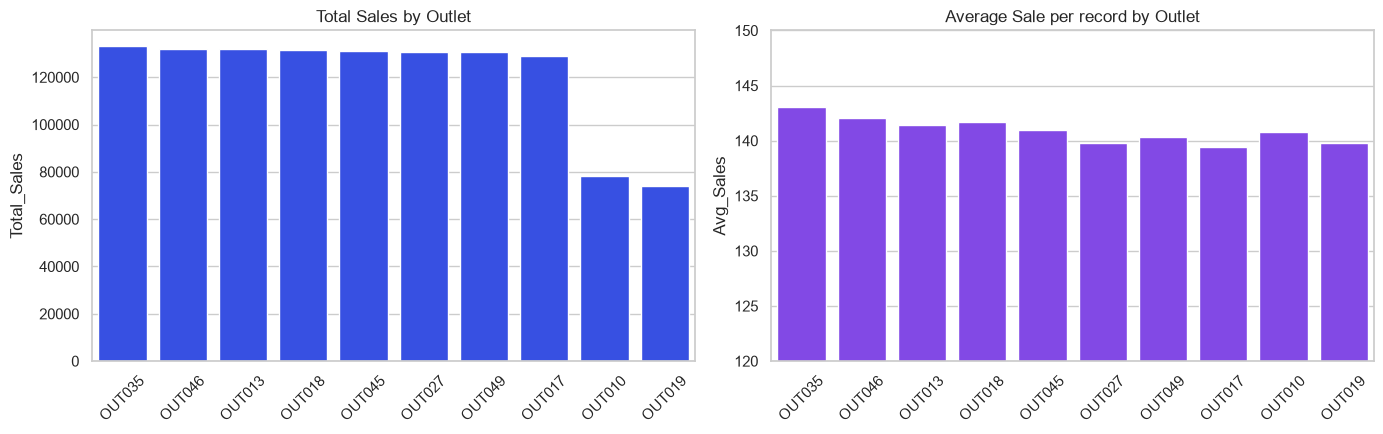

In [17]:
# --- Products: top 100 vs bottom 100 by average sale (products with at least 4 records) ---
prod = df.groupby('Item Identifier').agg(
    Avg_Sales=('Sales', 'mean'), Total_Sales=('Sales', 'sum'), Records=('Sales', 'size'),
    Visibility=('Item Visibility', 'mean'), Weight=('Item Weight', 'mean'), Rating=('Rating', 'mean'),
    Item_Type=('Item Type', 'first'))
prod = prod[prod['Records'] >= 4]
top100 = prod.nlargest(100, 'Avg_Sales'); bottom100 = prod.nsmallest(100, 'Avg_Sales')
compare = pd.DataFrame({'Top 100 products': top100[['Avg_Sales', 'Visibility', 'Weight', 'Rating']].mean(),
                        'Bottom 100 products': bottom100[['Avg_Sales', 'Visibility', 'Weight', 'Rating']].mean()}).round(3)
print(compare)
print()
print('Most common item types among TOP 100   :', top100['Item_Type'].value_counts().head(3).to_dict())
print('Most common item types among BOTTOM 100:', bottom100['Item_Type'].value_counts().head(3).to_dict())

# --- Outlets: best vs weakest ---
out = df.groupby('Outlet Identifier').agg(
    Total_Sales=('Sales', 'sum'), Avg_Sales=('Sales', 'mean'), Records=('Sales', 'size'),
    Avg_Rating=('Rating', 'mean'), Type=('Outlet Type', 'first'), Tier=('Outlet Location Type', 'first'),
    Size=('Outlet Size (clean)', 'first')).sort_values('Total_Sales', ascending=False).round(1)
print()
print(out)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=out.index, y=out['Total_Sales'], color='#1A3CFF', ax=axes[0]); axes[0].set_title('Total Sales by Outlet')
sns.barplot(x=out.index, y=out['Avg_Sales'], color='#7B2FFF', ax=axes[1]); axes[1].set_title('Average Sale per record by Outlet')
axes[1].set_ylim(120, 150)
for ax in axes: ax.tick_params(axis='x', rotation=45); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Insight 3.4:**
- **Products:** the top 100 products earn an average sale of about **254**, against only about **40** for the bottom 100 (more than 6 times higher). Yet the two groups look almost the same on visibility (0.068 vs 0.076), weight (12.7 vs 12.8) and rating (3.98 vs 3.94). Both lists also contain the same big item types (Snack Foods, Frozen Foods, Fruits and Vegetables, Dairy). So **every category has both high-value and low-value products**; the difference is the value of the individual product, not its category or its visibility.
- **Outlets:** the eight supermarkets are within about 3% of each other (about 129,000 to 133,000). The gap to OUT010 and OUT019 (Grocery Stores, about 74,000 to 78,000) is explained by **record count** (about 530 to 555 records vs about 930), because their *average sale per record* is about the same (around 140).

---
# Objective 4: Help Management Make Better Business Decisions
## Task 4.1: Which products are contributing more to sales?

  Item Identifier              Item Type   Sales
0           FDU12           Baking Goods  2371.0
1           FDT07  Fruits and Vegetables  2306.9
2           NCQ06              Household  2294.7
3           FDL58            Snack Foods  2111.7
4           NCB31              Household  2104.7
5           FDX31  Fruits and Vegetables  2104.5
6           FDF05           Frozen Foods  2103.1
7           FDR59                 Breads  2096.6
8           FDP28           Frozen Foods  2087.8
9           FDA04           Frozen Foods  2072.1


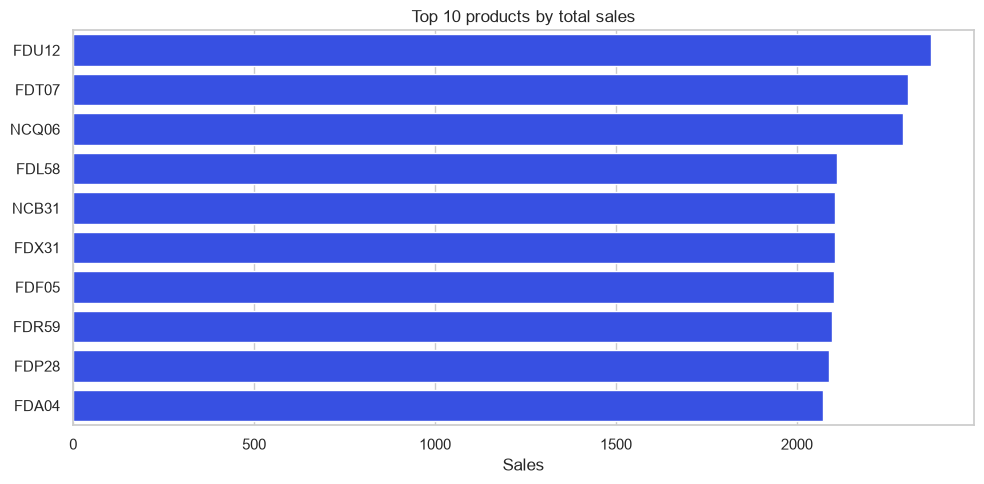

,Total_Sales,Share_%,Cumulative_%
Item Type,,,
Fruits and Vegetables,178124.1,14.8,14.8
Snack Foods,175433.9,14.6,29.4
Household,135976.5,11.3,40.7
Frozen Foods,118558.9,9.9,50.6
Dairy,101276.5,8.4,59.0
Canned,90706.7,7.5,66.5


In [18]:
top10 = df.groupby(['Item Identifier', 'Item Type'])['Sales'].sum().sort_values(ascending=False).head(10).reset_index()
print(top10.round(1))

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x='Sales', y='Item Identifier', color='#1A3CFF')
plt.title('Top 10 products by total sales'); plt.ylabel('')
plt.tight_layout(); plt.show()

share = type_perf[['Total_Sales', 'Share_%']].copy()
share['Cumulative_%'] = share['Share_%'].cumsum().round(1)
share.head(6)

**Insight 4.1:** The best-selling single products are **FDU12 (about 2,371, Baking Goods)**, **FDT07 (2,307, Fruits and Vegetables)** and **NCQ06 (2,295, Household)**. Note that Baking Goods has the lowest average sale as a category, yet holds the top product, which again shows that individual products matter more than categories. At category level, the **top 4 item types (Fruits and Vegetables, Snack Foods, Household, Frozen Foods) contribute about 50% of all sales**, so growth in these categories moves the whole business the most.

## Task 4.2: Which outlets and locations are performing better?

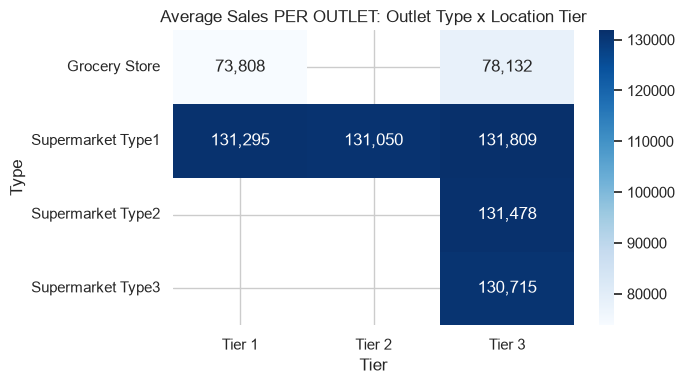

Top 3 outlets:
                   Total_Sales               Type    Tier   Size
Outlet Identifier                                               
OUT035                133103.9  Supermarket Type1  Tier 2  Small
OUT046                132113.4  Supermarket Type1  Tier 1  Small
OUT013                131809.0  Supermarket Type1  Tier 3   High

                      Total_Sales  Avg_Sales_per_Record  Records  Outlets  \
Outlet Location Type                                                        
Tier 3                   472133.0                 140.9     3350        4   
Tier 2                   393150.6                 141.2     2785        3   
Tier 1                   336397.8                 140.9     2388        3   

                      Sales_per_Outlet  Share_%  
Outlet Location Type                             
Tier 3                        118033.0     39.3  
Tier 2                        131050.0     32.7  
Tier 1                        112133.0     28.0  


In [19]:
pivot = out.pivot_table(index='Type', columns='Tier', values='Total_Sales', aggfunc='mean').round(0)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='Blues')
plt.title('Average Sales PER OUTLET: Outlet Type x Location Tier'); plt.tight_layout(); plt.show()

best = out.head(3)[['Total_Sales', 'Type', 'Tier', 'Size']]
print('Top 3 outlets:'); print(best)
print()
print(outlet_summary('Outlet Location Type'))

**Insight 4.2:** The top outlets are **OUT035 (133,104), OUT046 (132,113) and OUT013 (131,809)**, but the lead is tiny: all eight supermarkets sit within about 3% of each other. The heat map shows that **a supermarket earns about 131,000 in any tier**. Tier 3 has the highest *total* (472,133, about 39% of sales) only because it has 4 outlets, and Tier 1 looks lower only because one of its three outlets is a Grocery Store. The **two Grocery Stores (OUT019 in Tier 1, OUT010 in Tier 3) are the real low performers**, at about 58% of a supermarket.

## Task 4.3: Where can performance be improved?

Lowest 5 item types by TOTAL sales:
               Total_Sales  Records  Share_%
Item Type                                   
Seafood             9077.9       64      0.8
Breakfast          15596.7      110      1.3
Starchy Foods      21880.0      148      1.8
Others             22451.9      169      1.9
Hard Drinks        29334.7      214      2.4

Lowest 5 item types by AVERAGE sale per record:
                    Avg_Sales_per_Record  Records
Item Type                                        
Baking Goods                       126.4      648
Health and Hygiene                 130.8      520
Soft Drinks                        131.5      445
Others                             132.9      169
Hard Drinks                        137.1      214

Weakest outlets by total sales:
                   Total_Sales  Records  Avg_Sales               Type    Tier
Outlet Identifier                                                            
OUT017                129104.0      926      139.4  Supermark

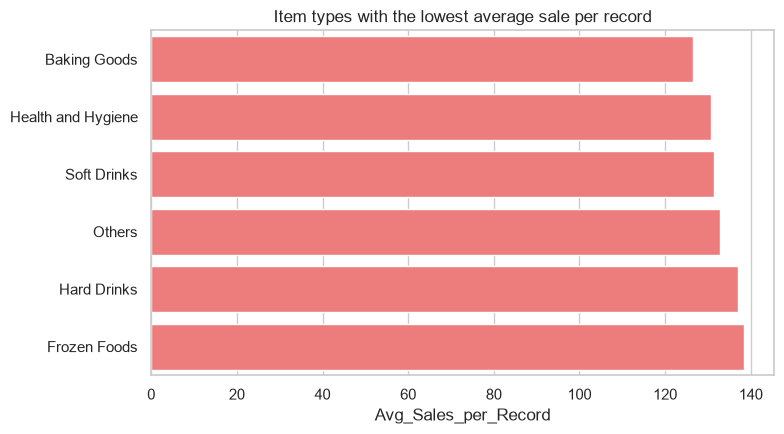

In [20]:
print('Lowest 5 item types by TOTAL sales:')
print(type_perf.sort_values('Total_Sales').head(5)[['Total_Sales', 'Records', 'Share_%']])
print()
print('Lowest 5 item types by AVERAGE sale per record:')
print(type_perf.sort_values('Avg_Sales_per_Record').head(5)[['Avg_Sales_per_Record', 'Records']])
print()
print('Weakest outlets by total sales:')
print(out.tail(3)[['Total_Sales', 'Records', 'Avg_Sales', 'Type', 'Tier']])
print()
low_rated = (df.groupby('Item Identifier').agg(Avg_Rating=('Rating', 'mean'), Total_Sales=('Sales', 'sum'), Records=('Sales', 'size'))
               .query('Avg_Rating < 3.5'))
print('Products with average rating below 3.5:', len(low_rated), 'of', df['Item Identifier'].nunique())
print('Records rated 3.0 or below            :', (df['Rating'] <= 3.0).sum(), f'({(df["Rating"] <= 3.0).mean()*100:.1f}% of all records)')

plt.figure(figsize=(8, 4.5))
sns.barplot(x=type_perf.sort_values('Avg_Sales_per_Record').head(6)['Avg_Sales_per_Record'],
            y=type_perf.sort_values('Avg_Sales_per_Record').head(6).index, color='#FF6B6B')
plt.title('Item types with the lowest average sale per record'); plt.ylabel('')
plt.tight_layout(); plt.show()

**Insight 4.3 (areas to improve):**
- **Small categories:** *Seafood (9,078)*, *Breakfast (15,597)*, *Starchy Foods (21,880)* and *Others (22,452)* contribute very little in total.
- **Low value per sale:** *Baking Goods (126.4)*, *Health and Hygiene (130.8)* and *Soft Drinks (131.5)* have the lowest average sale per record, even though they have many records.
- **Weaker outlets:** *OUT019* and *OUT010* (Grocery Stores) have the lowest total sales because they handle about 40% fewer records than the other outlets.
- **Customer satisfaction:** **95 of the 1,559 products** have an average rating below 3.5, and **617 records (7.2%)** are rated 3.0 or lower. These need a quality or service review.

## Task 4.4: Practical suggestions to improve sales and overall performance

Based on the evidence above, these are the recommended actions for management:

1. **Protect and grow the top categories.** Fruits and Vegetables, Snack Foods, Household and Frozen Foods bring in about half of all sales. Keep these always in stock and plan inventory around them first.
2. **Raise the value per sale in low-value categories.** Baking Goods, Health and Hygiene and Soft Drinks have the lowest average sale. Try combo packs, bundles with high-value items (Household, Dairy), and larger pack sizes.
3. **Close the gap at the two Grocery Stores (OUT010, OUT019).** Their average sale is equal to other outlets; they simply handle about 40% fewer transactions, so each earns only about 58% of a supermarket. Widen the product range, run local promotions and improve delivery coverage there, or evaluate upgrading them to the supermarket format.
4. **Use the supermarket format as the benchmark.** All eight supermarkets earn about the same (about 131,000 each, within 3%), so there is no weak supermarket to fix. Management effort is better spent on the Grocery Stores and on adding outlets.
5. **Expand with full supermarkets in any tier.** A supermarket earns about the same in Tier 1, 2 or 3 and in any size, so location tier alone should not decide where to open; use local demand and cost instead.
6. **Do not rely on visibility or weight alone to drive sales.** In this data they are not linked to sales, so use shelf space where demand already exists, not as a standalone lever. Instead, push the high-value products inside every category (top 100 products earn about 6 times the average sale of the bottom 100).
7. **Grow the small categories carefully.** Seafood, Breakfast and Starchy Foods are small. Test promotions on a few outlets before expanding stock.
8. **Review low-rated products.** The 95 products averaging below 3.5 should be checked for quality, packaging or availability issues.
9. **Fix data capture at source.** Missing item weights (from OUT019 and OUT027), zero visibility values, inconsistent fat-content labels and the conflicting size labels for OUT010, OUT017 and OUT045 should be corrected in the system so future reports are reliable.

In [21]:
summary = pd.DataFrame({
    'Metric': ['Total sales', 'Average sale per record', 'Average customer rating', 'Products sold', 'Item types', 'Outlets',
               'Top item type (sales)', 'Top outlet type (sales)', 'Top location tier (sales)', 'Top outlet (sales)',
               'Sales per supermarket outlet', 'Sales per Grocery Store outlet'],
    'Value': [f'{df["Sales"].sum():,.0f}', f'{df["Sales"].mean():.1f}', f'{df["Rating"].mean():.2f}',
              df['Item Identifier'].nunique(), df['Item Type'].nunique(), df['Outlet Identifier'].nunique(),
              type_perf.index[0], outlet_summary('Outlet Type').index[0], outlet_summary('Outlet Location Type').index[0], out.index[0],
              f"{out[out['Type'] != 'Grocery Store']['Total_Sales'].mean():,.0f}",
              f"{out[out['Type'] == 'Grocery Store']['Total_Sales'].mean():,.0f}"]})
summary

,Metric,Value
0,Total sales,"1,201,681"
1,Average sale per record,141.0
2,Average customer rating,3.97
3,Products sold,1559
4,Item types,16
5,Outlets,10
6,Top item type (sales),Fruits and Vegetables
7,Top outlet type (sales),Supermarket Type1
8,Top location tier (sales),Tier 3
9,Top outlet (sales),OUT035


---
# Final Conclusion
BlinkIT's sales are **driven by volume, outlet format and product mix, not by product features such as visibility, weight or rating**. About 50% of sales come from four item types. Supermarket Type1 delivers about two-thirds of total sales only because it has 6 of the 10 outlets: **every supermarket earns about 131,000, in any tier**, while each of the two Grocery Stores earns about 58% of that, because they handle fewer sales, not smaller ones. Management should therefore focus on **keeping the top categories strong, lifting the value per sale in low-value categories, pushing high-value products within every category, and closing the volume gap at the Grocery Stores**, while fixing the data-quality issues (missing weights, zero visibility, inconsistent fat-content and outlet-size labels) at the source.